# 01 · Data preparation: book catalogue (Book Depository)

**NLP project: Semantic Analysis and Intelligent Contextual Recommendation Systems (theme 3: book recommendation)**
**Part: person 1, Data Engineering**

## Goal of this notebook

Turn the raw **Book Depository** dataset (Kaggle `sp1thas/book-depository-dataset`, ≈ 1.1 million rows, 1.1 GB)
into a **clean reference catalogue** of about **12,000 books** that feeds the rest of the project:

| Output | Role |
|---|---|
| `data/processed/books_clean.parquet` | final catalogue: input of the enrichment (P2) and of the embeddings (P3) |
| `data/processed/books_sample.parquet` | stratified sample of 500 books with the **final schema** (fast development) |
| `data/reference/filtering_report.csv` | number of books after each filter (justification in the report) |
| `data/reference/category_stats.csv` | frequency of the catalogue's categories (basis of P2's categories → genres mapping) |
| `docs/figures/01_*.png` | EDA figures for the report and the slides |

## Guiding principle

The assignment requires a **semantic** analysis: the system compares the *meaning* of the user's answers with the *meaning* of the book descriptions.
The quality of the recommendation therefore depends directly on the **quality of the description text**. Every choice below
aims at keeping books whose description **tells the content** (plot, themes, atmosphere) rather than noise
(automatic reprints, press quotes, box sets, duplicate editions).

All the logic lives in `src/data_loader.py` (reusable by the app and the other notebooks). This notebook calls it **step by step**
and comments on each result. To regenerate everything at once: `python -m scripts.build_dataset`.

## 0. Imports and configuration

In [1]:
# --- Standard imports ---
import sys, json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Make the src/ folder importable from notebooks/ ---
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config
from src import data_loader as dl

# --- Figure style (exported to docs/figures for the report) ---
sns.set_theme(style="whitegrid", context="notebook")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 120)

def save_fig(fig, name):
    # Save each figure as a high-resolution PNG for the PDF report
    fig.savefig(config.FIGURES_DIR / f"01_{name}.png", dpi=150, bbox_inches="tight")

print("Racine du projet :", ROOT)

Racine du projet : /Users/maximedutertre/Desktop/Ecole/ECE/5eme annee/NLP/Projet/GenderBook-Projet-NLP


## 1. Downloading the dataset

The dataset is **public** on Kaggle: `kagglehub` downloads it without an API key. The raw CSVs go into `data/raw/`,
which is **excluded from Git** (`.gitignore`) because it is too heavy (1.1 GB). The function downloads nothing again if the files already exist.

Files provided:
- `dataset.csv`: one book (one *edition*) per row;
- `authors.csv`, `categories.csv`, `formats.csv`, `places.csv`: ID → name lookup tables (the `authors`, `categories`, `format` columns of the dataset contain **IDs**).

In [2]:
# Download (instantaneous if already present)
dl.download_raw_dataset()
for f in sorted(config.DATA_RAW.glob("*.csv")):
    print(f"{f.name:<16} {f.stat().st_size / 1e6:>10.1f} Mo")

authors.csv            18.0 Mo
categories.csv          0.1 Mo
dataset.csv          1142.3 Mo
formats.csv             0.0 Mo
places.csv              0.0 Mo


## 2. Loading and first look

Only **17 useful columns out of 28** are loaded (`usecols`): physical dimensions, weight, image checksums or the place of
publication bring nothing to a semantic recommendation. Everything is read as `str` and then converted explicitly: otherwise pandas
turns the ISBNs into floats and loses digits.

In [3]:
raw = dl.load_raw_books()          # ≈ 6 s for 1.1 GB
print(f"{raw.shape[0]:,} lignes × {raw.shape[1]} colonnes chargées")
raw.head(3).T

1,109,383 lignes × 17 colonnes chargées


,0,1,2
authors,[1],"[2, 3]",[4]
bestsellers-rank,49848,115215,11732
categories,"[214, 220, 237, 2646, 2647, 2659, 2660, 2679]","[235, 3386]","[358, 2630, 360, 2632]"
description,"SOLDIER FIVE is an elite soldier's explosive memoir of his time within the Special Air Service (SAS) and, in particu...","John Moran and Carl Williams were the two biggest rival drug barons in Australia. They certainly weren't partners, b...","Sir Phillip knew that Eloise Bridgerton was a spinster, and so he'd proposed, figuring that she'd be homely and unas..."
edition,NaN,NaN,New edition
for-ages,NaN,NaN,NaN
format,1,1,1
id,9781840189070,9781844547371,9788416327867
image-url,https://d1w7fb2mkkr3kw.cloudfront.net/assets/images/book/lrg/9781/8401/9781840189070.jpg,https://d1w7fb2mkkr3kw.cloudfront.net/assets/images/book/mid/9781/8445/9781844547371.jpg,https://d1w7fb2mkkr3kw.cloudfront.net/assets/images/book/lrg/9788/4163/9788416327867.jpg
imprint,Mainstream Publishing,NaN,NaN


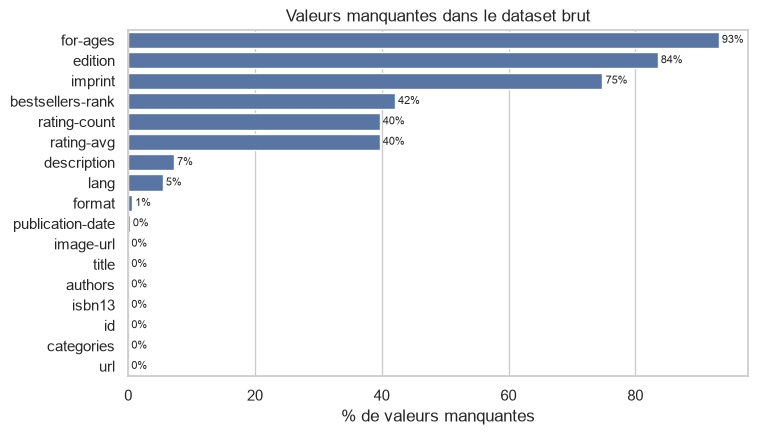

In [4]:
# Missing-value rate per column: guides the choice of usable attributes
missing = raw.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=missing.values * 100, y=missing.index, ax=ax, color="#4C72B0")
ax.set_xlabel("% de valeurs manquantes"); ax.set_ylabel("")
ax.set_title("Valeurs manquantes dans le dataset brut")
for i, v in enumerate(missing.values):
    ax.text(v * 100 + 0.5, i, f"{v:.0%}", va="center", fontsize=8)
save_fig(fig, "missing_values"); plt.show()

**Reading:**
- `description` is missing for only 7% of the books: it is **the** key column for semantic analysis, and it is well filled.
- `for-ages` is missing for **93%**: we cannot rely on it alone for the target audience, it will have to be **inferred from the categories** (section 6).
- `rating-avg` / `rating-count` (**Goodreads** ratings) are missing for 40%: these books are little known. They will be used as a notoriety filter and for the popularity score.
- `edition`, `imprint` are too sparse to be useful.

## 3. Exploring the raw data: language, format, descriptions, ratings

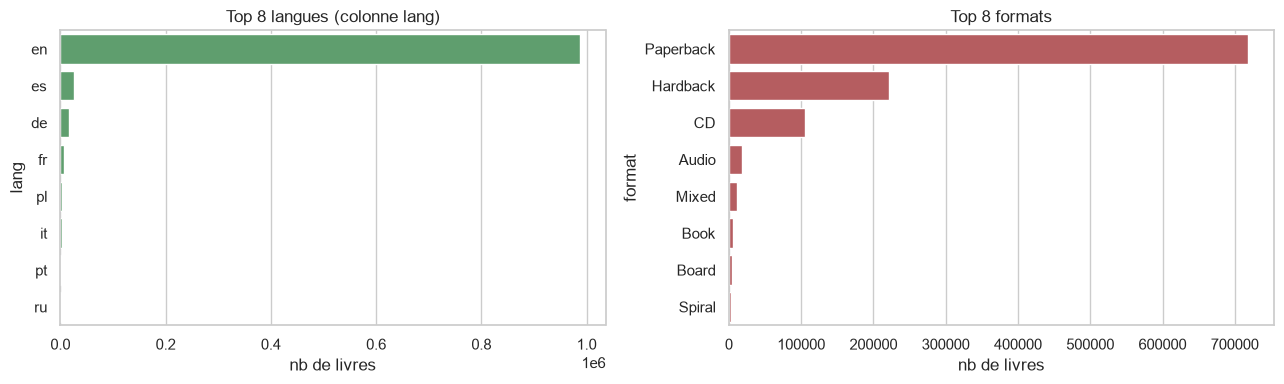

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Languages: only English is kept (English SBERT model + English interface)
lang = raw["lang"].value_counts().head(8)
sns.barplot(x=lang.values, y=lang.index, ax=axes[0], color="#55A868")
axes[0].set_title("Top 8 langues (colonne lang)"); axes[0].set_xlabel("nb de livres")

# Formats: the column holds an ID -> translated with formats.csv
formats = dl.load_lookup(config.RAW_FORMATS, "format_id", "format_name")
fmt = pd.to_numeric(raw["format"], errors="coerce").map(formats).value_counts().head(8)
sns.barplot(x=fmt.values, y=fmt.index, ax=axes[1], color="#C44E52")
axes[1].set_title("Top 8 formats"); axes[1].set_xlabel("nb de livres")
plt.tight_layout(); save_fig(fig, "lang_format"); plt.show()

89% of the books are in English. As for formats, there are **≈ 105,000 audio CDs** as well as calendars, maps, games, etc.
We only keep **Paperback** and **Hardback**: these are books to read, and their descriptions describe narrative content.

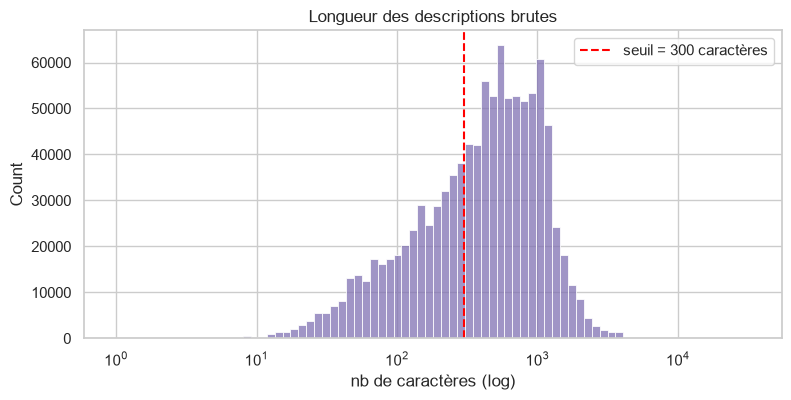

count    1029296.0
mean         561.0
std          490.0
min            1.0
25%          189.0
50%          441.0
75%          813.0
max        32709.0
Name: description, dtype: float64


In [6]:
# Distribution of description length (in characters, log scale)
desc_len = raw["description"].dropna().str.len()
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(desc_len, bins=80, log_scale=True, ax=ax, color="#8172B3")
ax.axvline(config.MIN_DESC_CHARS, color="red", ls="--", label=f"seuil = {config.MIN_DESC_CHARS} caractères")
ax.set_title("Longueur des descriptions brutes"); ax.set_xlabel("nb de caractères (log)"); ax.legend()
save_fig(fig, "raw_description_length"); plt.show()
print(desc_len.describe().round(0))

### "One-size-fits-all" descriptions: a trap for semantic analysis

By counting the descriptions that are **identical** across books, we discover generic texts repeated thousands of times.
They are automatic public-domain reprints ("facsimile reprint", "Print on Demand"…) or notebooks sold as books.
They say **nothing** about the content: all these books would get the same embedding, and a user query could be
"similar" to them by chance. They are detected with regex patterns (`BOILERPLATE_PATTERNS`).

**Sentence-by-sentence removal (`strip_boilerplate`)**: we do not throw away the whole description as soon as a pattern appears.
Only the generic **sentences** are removed, then the 300-character threshold is applied to the remaining text.
This way the blurb of *The Wizard of Oz* is kept, and only its sentence "*The original book has been in the public domain since 1956*" disappears.
A reprint whose description was ONLY generic text falls below the threshold and is discarded.

> *Review feedback (PR #1)*: the 1st version removed every description containing "public domain", which lost real descriptions.
> The report step also mixed two filters: out of the 337,000 rows removed, ≈ 295,000 were removed by the **length threshold** and only ≈ 42,000 by the generic patterns.
> The two steps are now logged separately.

In [7]:
# The "public domain" pattern alone no longer eliminates a good description: only the sentence is removed
oz = ("Dorothy is swept away to the magical land of Oz. The original book has been in the public "
      "domain in the US since 1956. She meets a scarecrow, a tin man and a lion.")
print("AVANT :", oz, "\nAPRÈS:", dl.strip_boilerplate(oz))

AVANT : Dorothy is swept away to the magical land of Oz. The original book has been in the public domain in the US since 1956. She meets a scarecrow, a tin man and a lion. 
APRÈS: Dorothy is swept away to the magical land of Oz. She meets a scarecrow, a tin man and a lion.


In [8]:
dup = raw.loc[raw["lang"] == "en", "description"].dropna().value_counts()
print(f"{(dup >= 3).sum():,} textes répétés ≥ 3 fois, qui couvrent {dup[dup >= 3].sum():,} livres\n")
top_dup = dup.head(6).rename("nb_livres").reset_index().rename(columns={"description": "texte (début)"})
top_dup["texte (début)"] = top_dup["texte (début)"].str[:110] + "…"
top_dup

12,485 textes répétés ≥ 3 fois, qui couvrent 141,070 livres



,texte (début),nb_livres
0,"This book is a facsimile reprint and may contain imperfections such as marks, notations, marginalia and flawed…",16634
1,"This scarce antiquarian book is a facsimile reprint of the original. Due to its age, it may contain imperfecti…",5843
2,"This work has been selected by scholars as being culturally important, and is part of the knowledge base of ci…",4575
3,"This is a Print on Demand title. This book may have occasional imperfections such as missing or blurred pages,…",4549
4,This work has been selected by scholars as being culturally important and is part of the knowledge base of civ…,2394
5,"This work has been selected by scholars as being culturally important, and is part of the knowledge base of ci…",2114


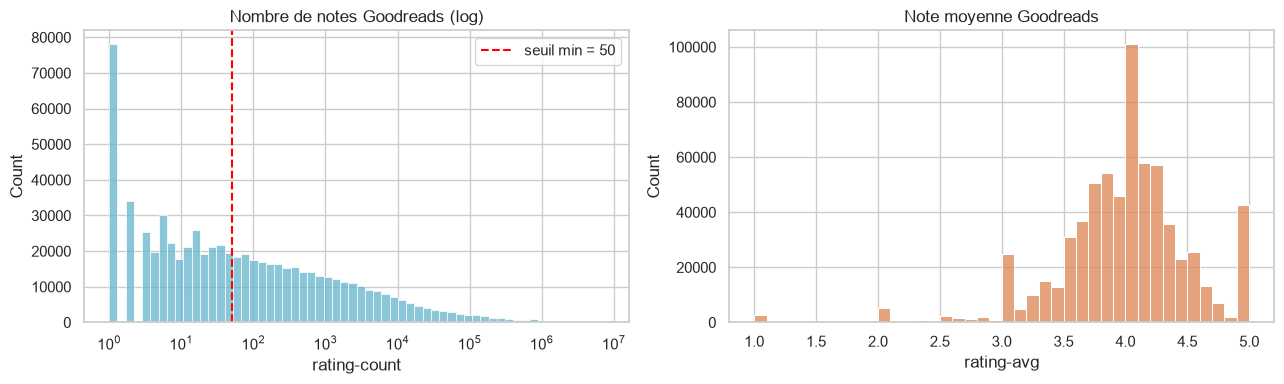

Médiane du nb de notes : 39 | max : 7,377,337


In [9]:
# Goodreads ratings: very skewed distribution (a few best-sellers with several million ratings)
rc = pd.to_numeric(raw["rating-count"], errors="coerce").dropna()
ra = pd.to_numeric(raw["rating-avg"], errors="coerce").dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(rc, bins=60, log_scale=True, ax=axes[0], color="#64B5CD")
axes[0].axvline(config.MIN_RATING_COUNT, color="red", ls="--", label=f"seuil min = {config.MIN_RATING_COUNT}")
axes[0].set_title("Nombre de notes Goodreads (log)"); axes[0].legend()
sns.histplot(ra, bins=40, ax=axes[1], color="#DD8452")
axes[1].set_title("Note moyenne Goodreads")
plt.tight_layout(); save_fig(fig, "raw_ratings"); plt.show()
print("Médiane du nb de notes :", int(rc.median()), "| max :", f"{int(rc.max()):,}")

## 4. Cleaning the description text

### 4.1 Minimal cleaning (`clean_description`)
HTML entities (`&amp;` → `&`), leftover tags, URLs, Unicode normalisation (NFKC), multiple spaces.

**What we deliberately do NOT do here:** lowercasing, stopword removal, lemmatisation.
Contextual models (BERT/SBERT) were trained on natural text. The meaning of *"not a happy ending"* depends on *not*,
and removing stopwords would degrade the embedding. This "classic" preprocessing is reserved for the TF-IDF / GloVe baselines (P3).

### 4.2 Removing marketing text (`src/marketing.py`)
≈ 7% of the descriptions start with **press quotes** (*"A chilling thriller" --Booklist*) or **banners**
(*INSTANT #1 NEW YORK TIMES BESTSELLER*), and many end with a *Praise for…* section. These sentences talk about the book's **success**,
not its **content**: they would artificially bring all best-sellers closer together in the embedding space.

**The real difficulty is knowing where the attribution ends.** In *"A premium delivery." --People Meghan doesn't know Agatha*,
"People" is a magazine but "Meghan" is already the plot. A "sequence of capitalised words" regex cannot tell the difference.
The `MarketingStripper` therefore uses **knowledge taken from the dataset itself**:
1. a list of **press publications** (People, Booklist, Kirkus, The Guardian…);
2. the **631,000 author names** of `authors.csv`, to recognise "--Stephen King" or "--Alain de Botton";
3. the **1.1 million titles** of the dataset, to know where "*author of The Statistical Probability of Love at First Sight*" ends;
4. a **cautious** fallback when nothing is recognised: we prefer leaving 2 attribution words rather than cutting a sentence.

Safety rules:
- a banner ("The #1 New York Times bestselling…") is removed **only if it forms a standalone segment**: never if it is followed by a lowercase word ("…debut novel that introduced Khaled Hosseini"), which would cut the sentence;
- a quote followed by a dash but **without an identifiable source** (lowercase word) is a quote **from the story** and is left untouched (*known as Hoja--"master"--a man who…*).

The version with minimal cleaning only is kept in `description_raw` (traceability).

> *Review feedback (PR #1)*: the 1st version, purely regex-based, cut content (*The Secrets She Keeps* → "doesn't know Agatha") or left leftovers
> (*Tell Me Three Things*). The evaluation below on the 12,000 descriptions measures the improvement.

In [10]:
examples = [
    'THE INSTANT NEW YORK TIMES BESTSELLING DEBUT PSYCHOLOGICAL THRILLER YOU CAN\'T MISS! The perfect marriage? Or the perfect lie? '
    '"A hair-raising debut, both unsettling and addictive." --Mary Kubica, New York Times bestselling author of The Good Girl '
    '"This is one readers won\'t be able to put down." --Booklist (starred review) Jack and Grace seem like the perfect couple.',
    'A daring new departure from the creator of The Vampire Chronicles ("unrelentingly erotic... unforgettable"--The Washington Post). '
    'A whole new world&mdash;modern, sleek, high-tech.<br/>Visit www.example.com',
]
# "Full" stripper: knows the dataset's author names and titles
stripper = dl.build_marketing_stripper(raw)
examples += [
    '"Two terrific female characters." --Stephen King "A premium delivery." --People '
    "Meghan doesn't know Agatha, but Agatha knows Meghan.",
    'A New York Times Bestseller "Here are three things about this book." --Jennifer E. Smith, author of '
    'The Statistical Probability of Love at First Sight With the perfect mix of comedy and tragedy, love and loss...',
    'A brilliant inventor known as Hoja--"master"--a man who is his exact double.',
    "The #1 New York Times bestselling debut novel that introduced Khaled Hosseini to millions of readers.",
]
for e in examples:
    print("AVANT :", e, "\nAPRÈS:", stripper(dl.clean_description(e)), "\n")

AVANT : THE INSTANT NEW YORK TIMES BESTSELLING DEBUT PSYCHOLOGICAL THRILLER YOU CAN'T MISS! The perfect marriage? Or the perfect lie? "A hair-raising debut, both unsettling and addictive." --Mary Kubica, New York Times bestselling author of The Good Girl "This is one readers won't be able to put down." --Booklist (starred review) Jack and Grace seem like the perfect couple. 
APRÈS: The perfect marriage? Or the perfect lie? Jack and Grace seem like the perfect couple. 

AVANT : A daring new departure from the creator of The Vampire Chronicles ("unrelentingly erotic... unforgettable"--The Washington Post). A whole new world&mdash;modern, sleek, high-tech.<br/>Visit www.example.com 
APRÈS: A daring new departure from the creator of The Vampire Chronicles. A whole new world—modern, sleek, high-tech. 

AVANT : "Two terrific female characters." --Stephen King "A premium delivery." --People Meghan doesn't know Agatha, but Agatha knows Meghan. 
APRÈS: Meghan doesn't know Agatha, but Agatha kno

**Systematic evaluation.** A description that starts with a **lowercase letter** is the symptom of a cut in the middle of a sentence.
We compare the old version (regex only) and the new one on the raw text of the catalogue descriptions.
We also inspect the most modified texts (`len(description_raw) - len(description)`), as suggested in the review.

In [11]:
from src.marketing import MarketingStripper
cat_tmp = dl.load_books(config.BOOKS_CLEAN)          # existing catalogue (raw text in description_raw)
raw_desc = cat_tmp["description_raw"]
naive = MarketingStripper()                          # without lists: cautious heuristics
new_desc = raw_desc.map(stripper)
starts_lower = lambda s: int(s.str.match(r"^[a-z]").sum())
print(f"Descriptions modifiées              : {(raw_desc != new_desc).sum():,} / {len(raw_desc):,}")
print(f"Débuts en minuscule — texte brut     : {starts_lower(raw_desc)}")
print(f"                    — sans listes   : {starts_lower(raw_desc.map(naive))}")
print(f"                    — avec listes   : {starts_lower(new_desc)}   (≈ 235 avec la 1re version regex)")
diff = (raw_desc.str.len() - new_desc.str.len()).sort_values(ascending=False)
for i in diff.index[:5]:
    print(f"\n[-{diff[i]} car.] {cat_tmp.title[i]}\n  BRUT : {raw_desc[i][:200]}…\n  NLP  : {new_desc[i][:200]}…")

Descriptions modifiées              : 1,477 / 12,000
Débuts en minuscule — texte brut     : 9


                    — sans listes   : 31
                    — avec listes   : 28   (≈ 235 avec la 1re version regex)

[-1814 car.] Miller's Valley
  BRUT : NEW YORK TIMES BESTSELLER - In a small town on the verge of big change, a young woman unearths deep secrets about her family and unexpected truths about herself. Filled with insights that are the hall…
  NLP  : In a small town on the verge of big change, a young woman unearths deep secrets about her family and unexpected truths about herself. Filled with insights that are the hallmark of Anna Quindlen's best…

[-1546 car.] Battle Hymn of the Tiger Mother
  BRUT : "[E]ntertaining, bracingly honest and, yes, thought-provoking."--The New York Times Book Review At once provocative and laugh-out-loud funny, Battle Hymn of the Tiger Mother ignited a global parenting…
  NLP  : At once provocative and laugh-out-loud funny, Battle Hymn of the Tiger Mother ignited a global parenting debate with its story of one mother's journey in strict par

The largest removals are **"Praise for …"** sections made up entirely of reviews: this is the intended behaviour.
The ≈ 20 remaining lowercase starts are mostly **leftover attributions not removed** ("*via Twitter*", "*former secretary of the navy*"), hence **cautious**
errors: we leave a few marketing words rather than cutting content.

## 5. Categories: keeping only "leisure reading"

The dataset uses the booksellers' nomenclature (≈ 2,900 categories): it contains *Contemporary Fiction* as well as
*Accounting Software* or *Diets & Dieting*. For a system that recommends according to **literary preferences**, each
category is classified into 4 groups with **transparent** regex rules (`classify_category`):

| Group | Examples | Decision |
|---|---|---|
| `fiction` | Contemporary Fiction, Fantasy, Manga, Poetry, Children's Fiction | **keep** |
| `nonfiction` | Memoirs, History, True Crime, Popular Science, Philosophy | **keep** (narrative reading) |
| `excluded` | Cookery, Computing, Teaching Resources, Dictionaries, Medicine | exclude |
| `neutral` | Literary Studies, Children's Books… | does not count |

**Decision rule per book:** at least 1 "leisure" category, and at least as many leisure categories as excluded ones.
The exclusion test is done **before** the fiction test, and fiction false positives are ruled out (*True Crime*, *Criminology*, *Teenagers: Advice For Parents*).

In [12]:
cat_names = dl.load_lookup(config.RAW_CATEGORIES, "category_id", "category_name")
classes = pd.Series({n: dl.classify_category(n) for n in set(cat_names.values())}, name="classe")
print(classes.value_counts(), "\n")
# A few examples of each class to check the rules by eye
for c in ["fiction", "nonfiction", "excluded", "neutral"]:
    print(f"{c:<11}:", classes[classes == c].sample(8, random_state=1).index.tolist())

classe
neutral       1351
excluded       735
nonfiction     393
fiction        106
Name: count, dtype: int64 

fiction    : ['Adventure Holidays', 'History Books for Kids', 'Animal Stories', 'Funny Books for Kids', 'Historical Crime', 'Cartoons', 'Fantasy', 'Funny Books & Stories']
nonfiction : ['Ancient Egyptian Religion & Mythology', 'Family Issues', 'Mind, Body, Spirit: Meditation & Visualisation', 'Gender Studies: Transsexuals & Hermaphroditism', 'Judaism: Life & Practice', 'Religious Groups: Social & Cultural Aspects', 'Conservation Of The Environment', 'Autobiography: Literary']
excluded   : ['Pre-clinical Medicine: Basic Sciences', 'Waste Management', 'Flower Arranging & Floral Crafts', 'Applied Linguistics For ELT', 'Management Of Land & Natural Resources', 'Road Transport & Haulage Trades', 'Microbiology (non-medical)', 'Production Engineering']
neutral    : ['Rhyming & Wordplay', 'Arms Trade', 'Ultrasonics', 'Art & Photography', 'Bonsai', 'Reflexology', 'Hockey', 'Ethical Iss

## 6. Target audience: Children / Young Adult / Adult

The questionnaire asks for the target audience: this information is needed to **filter**. But `for-ages` is only filled in for 7% of the books.
`infer_audience` rule:
1. if `for-ages` exists, it is used (minimum age < 12 → *Children*, 12-17 → *Young Adult*, ≥ 18 → *Adult*);
2. otherwise we look at the categories: *Teenage / Young Adult* → *Young Adult*; *Children's / for Kids / Picture Books* → *Children*;
3. otherwise *Adult*.

In [13]:
tests = [("9-12", []), ("12-17", []), (None, ["Romance Books for Teenagers"]),
         (None, ["Fantasy Books for Kids", "Adventure Books"]), (None, ["Crime Fiction"])]
for ages, cats in tests:
    print(f"for-ages={str(ages):<6} catégories={cats!s:<48} -> {dl.infer_audience(ages, cats)}")

for-ages=9-12   catégories=[]                                               -> Children
for-ages=12-17  catégories=[]                                               -> Young Adult
for-ages=None   catégories=['Romance Books for Teenagers']                  -> Young Adult
for-ages=None   catégories=['Fantasy Books for Kids', 'Adventure Books']    -> Children
for-ages=None   catégories=['Crime Fiction']                                -> Adult


## 7. Full catalogue construction pipeline

`build_catalogue()` chains all the steps and **logs the number of books left after each one**.
The steps not presented yet:

- **Notoriety threshold** `rating_count ≥ 50`: fewer ratings = confidential book or poor metadata. This numeric filter is applied **before** the more costly text cleaning.
- Raw **length threshold** (≥ 300 characters), then generic and marketing text removed, then again ≥ 300 characters of **content**.
- **Canonical author spelling** (section 8 bis).
- **Box sets / bundles** (*Box Set*, *Bundle*, *Books 1-3*): removed, because a box set is not *one* reading experience and its description mixes several plots.
- **Spin-off products** (*Harry Potter: A Pop-Up Book*, *Page to Screen*, *Film Wizardry*, official guides, art books, sticker books…): these are not reading experiences.
  The list of patterns is deliberately **precise**: broad patterns such as "guide to", "the art of" or "companion" would remove *The Art of War*, *The Hitchhiker's Guide to the Galaxy*
  or "companion" novels such as *Lying Out Loud: A Companion to the Duff*. "Corporate" authors (Warner Bros, Scholastic…) are also a signal.
- **Merging editions** (section 8): a single row per work.
- Remaining **shared descriptions**: removed (generic publisher texts).
- **Cap of 8 books per author**: without it, James Patterson, Stephen King or a manga series would take hundreds of places, which would reduce the diversity of the recommendations. The "main author" is the author of the list who is most frequent in the corpus, so as not to count the illustrator or the translator.
- **Checking the language** of the description (`langdetect`, fixed seed): `lang` describes the book, but some descriptions are in another language.
- **Final selection**: the 12,000 most rated works.

In [14]:
catalogue, report, cat_stats = dl.build_catalogue(raw=raw)

0. Raw dataset                                 1,109,383  all rows of dataset.csv


1. lang == 'en'                                  986,575  English SBERT model + English UI


2. title & description not null                  952,244  nothing to embed otherwise


3. format in Paperback/Hardback                  832,881  drop audio CDs, calendars, toys...


4. rating_count >= 50                            232,731  known books with reliable ratings
5. raw description >= 300 chars                  136,531  short blurbs carry too little meaning


6. not only boilerplate                          135,877  generic sentences removed in 1,018 texts; drop texts that were only boilerplate


... (4 outputs left out)

11. drop companion products                      110,303  pop-up books, film tie-in guides, art books...


12. merge editions of the same work               95,877  same title+author, or same Goodreads ratings + similar title/author
13. drop shared descriptions                      93,724  generic publisher texts


14. max 8 books per author                        80,718  avoid catalogue saturation by prolific authors / manga series
15. top 13,799 candidates by rating_count         13,799  well-known books: richer descriptions, recognisable in the demo


16. description really in English                 13,709  langdetect (seed fixed)
17. final catalogue (top 12,000)                  12,000  target size reached


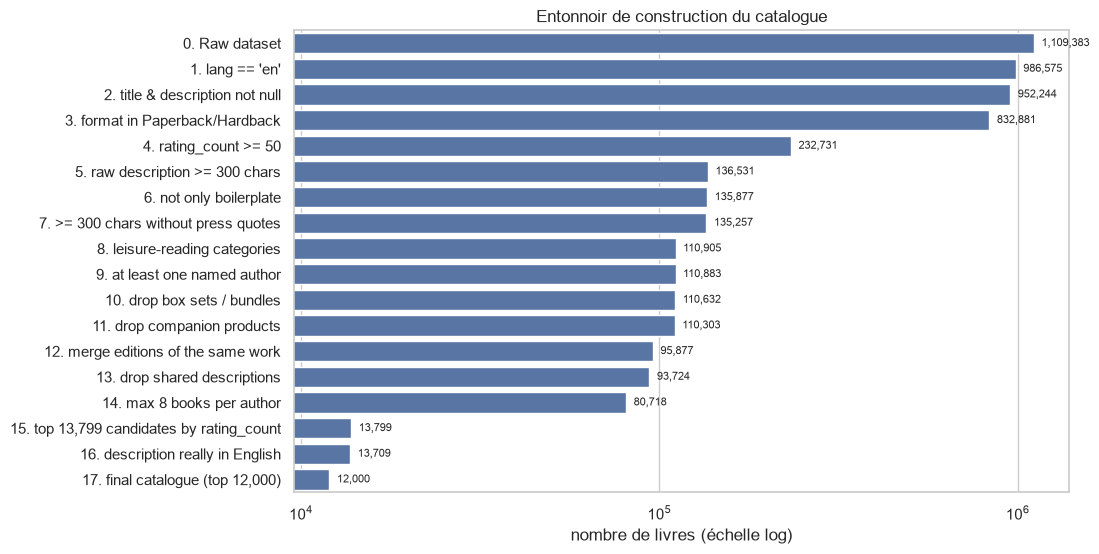

,step,rows,comment
0,0. Raw dataset,1109383,all rows of dataset.csv
1,1. lang == 'en',986575,English SBERT model + English UI
2,2. title & description not null,952244,nothing to embed otherwise
3,3. format in Paperback/Hardback,832881,"drop audio CDs, calendars, toys..."
4,4. rating_count >= 50,232731,known books with reliable ratings
5,5. raw description >= 300 chars,136531,short blurbs carry too little meaning
6,6. not only boilerplate,135877,"generic sentences removed in 1,018 texts; drop texts that were only boilerplate"
7,7. >= 300 chars without press quotes,135257,enough content once marketing is removed
8,8. leisure-reading categories,110905,"fiction + narrative non-fiction, no textbooks/cookery/IT..."
9,9. at least one named author,110883,needed for display & dedup


In [15]:
# Filtering funnel (figure for the report)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=report, x="rows", y="step", ax=ax, color="#4C72B0")
ax.set_xscale("log"); ax.set_xlabel("nombre de livres (échelle log)"); ax.set_ylabel("")
ax.set_title("Entonnoir de construction du catalogue")
for i, v in enumerate(report["rows"]):
    ax.text(v * 1.05, i, f"{v:,}", va="center", fontsize=8)
save_fig(fig, "filtering_funnel"); plt.show()
report

### Why 12,000 books, selected by popularity?

The assignment recommends **at least 60 books**. We keep 12,000 for 4 reasons:
1. **Coverage**: enough books for every profile (children's fantasy, philosophical essay, historical romance…) to have good candidates.
2. **Cost**: 12,000 MiniLM embeddings are computed in a few minutes on CPU, and search by matrix product stays instantaneous in the app.
3. **Quality**: widely read books have richer editorial descriptions, and their ratings are reliable.
4. **Demo and evaluation**: well-known books make it possible to judge by eye whether a recommendation is relevant, and the user can mention a book or an author they like.

Accepted trade-off (to be discussed in the report): a **bias towards popular books**. It is partly offset by the per-author cap
and by the questionnaire's "best-sellers ↔ hidden gems" Likert, which adjusts the weight of popularity in the score (P4).

In [16]:
# How many works would remain depending on the notoriety threshold? (on the pool before the final selection)
print("Plus petit nombre de notes dans le catalogue final :", f"{catalogue['rating_count'].min():,}")
print("Nombre de notes médian :", f"{int(catalogue['rating_count'].median()):,}")

Plus petit nombre de notes dans le catalogue final : 5,185
Nombre de notes médian : 14,143


## 8. Focus: merging multiple editions

The dataset lists **editions**, not works: *Pride and Prejudice* appears dozens of times (Penguin, Wordsworth, large print…).
Without merging, a "Regency romance" query would return the same novel 3 times in the top 3.

Two difficulties:
- authors have different IDs depending on the edition (*J.K. Rowling*, *J. K. Rowling*, *J K Rowling*). We use a **normalised key** (`jkrowling`);
- titles vary (*Philosopher's Stone* / *Sorcerer's Stone*, *Dune : Deluxe Edition*).

**Algorithm (`dedup_editions`, union-find)**: two rows are the same work if
- **(a)** same normalised title (without edition mentions, apostrophes deleted, hyphens → spaces, compared **without spaces**) **and** at least one shared author; **or**
- **(b)** nearly identical Goodreads ratings (Goodreads aggregates ratings **per work**: number of ratings within ±2%, average within ±0.05) **and** similar titles
  (Jaccard of the meaningful words ≥ 0.5, or one title contained in the other if the shorter one has ≥ 3 words, or 2 words **and** a shared author).

The links are grouped transitively (union-find). In each group we keep the most rated **standard** edition,
and the main author is **the majority author across all the editions**. The most rated edition of *Pride and Prejudice* is credited to "Jane Aust**i**n" (typo),
but the vast majority of the editions are credited to "Jane Austen".

> *Review feedback (PR #1)*: 6 duplicates caused by punctuation remained (*Cat's Eye* / *Cats Eye*, *Yellow Wall-paper* / *Yellow Wallpaper*) and a few caused by spaces
> (*Daddy-Long-Legs* / *Daddy Long Legs*, *The Wasteland* / *The Waste Land*). None remain (checked by a test).
> By tightening the inclusion rule, the suspicious groups also went down from 28 to 14: *Civil War* (Lucan) is no longer merged with *Spider-Man: Miles Morales: Civil War II*.

> **Documented iteration:** a first version accepted "same author" without a similar title in rule (b).
> Inspection revealed wrong merges (two different Lee Child novels with ratings within ±2% of each other). The current rule always requires a similar title:
> the suspicious groups (titles without any shared word) went down from 1,606 to 23 out of ≈ 69,000 groups, and these 23 cases are mostly real translations (*Inferno* / *The Divine Comedy : Inferno*).

In [17]:
# Demo on all the English editions of Harry Potter book 1
hp = raw[raw["title"].str.contains("Harry Potter and the (?:Philosopher|Sorcerer)", na=False, regex=True)
         & (raw["lang"] == "en")].copy()
authors_map = dl.load_lookup(config.RAW_AUTHORS, "author_id", "author_name")
hp["rating_count"] = pd.to_numeric(hp["rating-count"], errors="coerce")
hp["rating_avg"] = pd.to_numeric(hp["rating-avg"], errors="coerce")
hp = hp[hp["rating_count"] >= 1000]
hp["authors_list"] = hp["authors"].map(dl.parse_id_list).map(lambda ids: [authors_map[i] for i in ids if authors_map.get(i)])
hp["author_keys"] = hp["authors_list"].map(lambda l: [dl.author_key(a) for a in l])
hp["title"] = hp["title"].map(dl.clean_title)
hp["description"] = hp["description"].fillna("")
groups = dl.dedup_editions(hp, return_groups=True)
print(f"{len(hp)} éditions -> {groups['work_id'].nunique()} œuvre(s)")
groups[["title", "authors_list", "rating_count", "rating_avg", "is_special_edition", "work_id"]].head(12)

25 éditions -> 1 œuvre(s)


,title,authors_list,rating_count,rating_avg,is_special_edition,work_id
18,Harry Potter and the Sorcerer's Stone,[J. K. Rowling],7363346.0,4.48,False,0
9,Harry Potter and the Philosopher's Stone,[J.K. Rowling],7363346.0,4.48,False,0
11,Harry Potter and the Philosopher's Stone,[J.K. Rowling],7363346.0,4.48,False,0
12,Harry Potter and the Philosopher's Stone,[J.K. Rowling],7363346.0,4.48,False,0
15,Harry Potter and the Philosopher's Stone (Irish),[J.K. Rowling],7363346.0,4.48,False,0
5,Harry Potter and the Philosopher's Stone,[J. K. Rowling],7343357.0,4.48,False,0
8,Harry Potter and the Philosopher's Stone,[J.K. Rowling],7343357.0,4.48,False,0
4,Harry Potter and the Philosopher's Stone,"[Stephen Fry, J. K. Rowling]",7343357.0,4.48,False,0
0,Harry Potter and the Sorcerer's Stone,"[Jim Dale, J K Rowling]",7248094.0,4.48,False,0
3,Harry Potter and the Sorcerer's Stone,"[J K Rowling, MinaLima Design]",7248094.0,4.48,False,0


In [18]:
# The most "merged" works of the final catalogue
catalogue.sort_values("n_editions", ascending=False)[["title", "main_author", "n_editions"]].head(10)

,title,main_author,n_editions
34,Romeo and Juliet,William Shakespeare,101
341,The Art of War,Sun Tzu,73
976,Tao Te Ching : The Way of Nature and Its Virtues,Lao Tzu,67
2015,Bhagavad Gita,Sir Edwin Arnold,48
640,Around The World In Eighty Days,Jules Verne,42
159,Macbeth,William Shakespeare,33
8,Pride and Prejudice,Jane Austen,31
188,A Christmas Carol,Charles Dickens,30
308,The Wonderful Wizard of Oz,Lyman Frank Baum,27
67,Frankenstein,Mary Shelley,26


In [19]:
# Check: no title + author duplicates left (punctuation and spaces ignored)
key = (catalogue["title"].map(lambda t: dl.normalize_title(dl.display_title(t)).replace(" ", ""))
       + "|" + catalogue["main_author"].map(dl.author_key))
print("Doublons titre + auteur :", key.duplicated().sum())
print("Pride and Prejudice ->", catalogue.loc[catalogue["title"] == "Pride and Prejudice", "main_author"].tolist())

Doublons titre + auteur : 0
Pride and Prejudice -> ['Jane Austen']


## 8 bis. A single spelling per author

The dataset gives a **different ID** to each spelling of the same author: *J.K. Rowling*, *J. K. Rowling*, *J K Rowling*, or *A A Milne* / *A. A. Milne*.
In the 1st version, 119 authors of the catalogue had several spellings. Consequences for the rest of the project:
- the questionnaire's **favourite author** (centroid of the author's books, P4) only found part of their books;
- **excluding an author** only removed one Harry Potter out of 7.

**Fix (in two steps):**
1. **in the catalogue**: each author is replaced by their **canonical** spelling, the most frequent among the variants with the same normalised key (`jkrowling`). The whole team sees a single spelling;
2. **in the utilities**: `find_author`, `get_books_by_author` and `apply_constraints` compare the **normalised keys**. An input such as "jk rowling" or "J.K.Rowling" is therefore recognised exactly, before fuzzy matching.

In [20]:
ex = catalogue[["authors"]].explode("authors").dropna()
n_variants = (ex.groupby(ex["authors"].map(dl.author_key))["authors"].nunique() > 1).sum()
print("Auteurs avec plusieurs orthographes dans le catalogue :", n_variants, "(119 dans la 1re version)")
canon = dl.canonical_author_names([["J.K. Rowling"], ["J.K. Rowling"], ["J. K. Rowling"], ["Jim Kay", "J K Rowling"]])
print("Exemple :", dl.canonicalize_authors(["Jim Kay", "J K Rowling"], canon))

Auteurs avec plusieurs orthographes dans le catalogue : 0 (119 dans la 1re version)
Exemple : ['Jim Kay', 'J.K. Rowling']


## 9. Exploratory analysis of the final catalogue

In [21]:
print(f"{len(catalogue):,} livres | {catalogue['main_author'].nunique():,} auteurs principaux distincts")
ct = pd.crosstab(catalogue["domain"], catalogue["audience"], margins=True)
ct

12,000 livres | 5,860 auteurs principaux distincts


audience,Adult,Children,Young Adult,All
domain,,,,
Fiction,6916,1319,1101,9336
Non-fiction,2423,121,120,2664
All,9339,1440,1221,12000


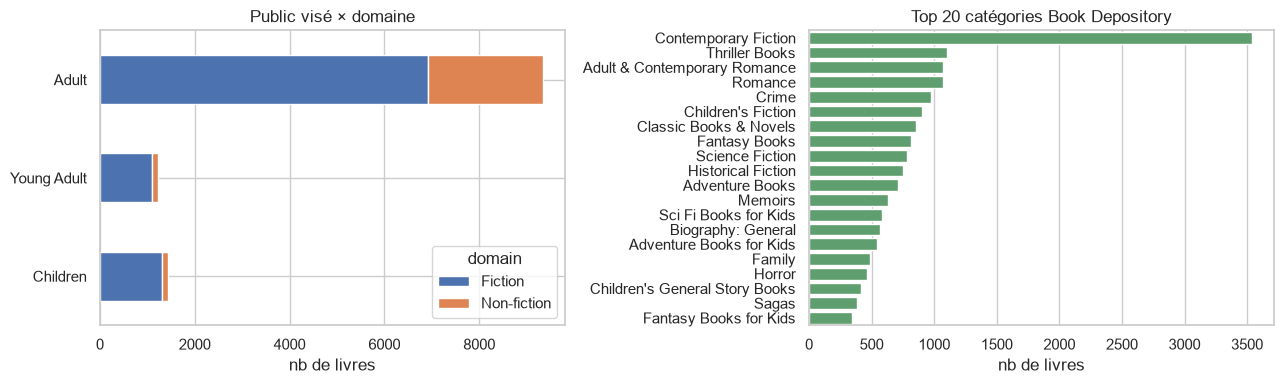

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# Domain × audience breakdown
pd.crosstab(catalogue["audience"], catalogue["domain"]).loc[list(config.AUDIENCES)].plot(
    kind="barh", stacked=True, ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Public visé × domaine"); axes[0].set_xlabel("nb de livres"); axes[0].set_ylabel("")
# Top categories (after merging duplicate labels such as "Thrillers" / "Thriller Books")
top_cats = cat_stats.drop_duplicates("n_books").head(20)
sns.barplot(data=top_cats, x="n_books", y="category", ax=axes[1], color="#55A868")
axes[1].set_title("Top 20 catégories Book Depository"); axes[1].set_xlabel("nb de livres"); axes[1].set_ylabel("")
plt.tight_layout(); save_fig(fig, "catalogue_audience_categories"); plt.show()

The catalogue is mostly adult fiction, with a significant share of **children's / Young Adult (≈ 22%)** and **narrative non-fiction (≈ 22%)**.
Every questionnaire profile therefore has candidates. The categories are numerous and redundant (*Thrillers* / *Thriller Books*):
this is why P2 groups them into ≈ 15 **semantic macro-genres** (file `category_stats.csv` provided).

### Description length in **tokens**: impact on the choice of model

SBERT models have a maximum length: **256 tokens** for `all-MiniLM-L6-v2`, 384 for `all-mpnet-base-v2`. Beyond that, the text is **truncated**.
We measure the real length of `embed_text` (title + description) with the model's **real tokenizer**, to know what share of the books is entirely "read" by the model.

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


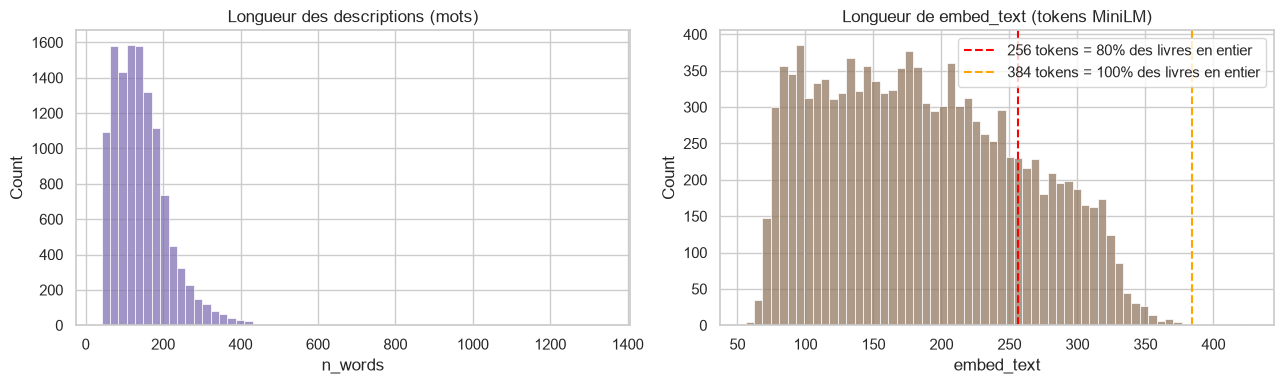

count    12000.0
mean       186.0
std         72.0
min         56.0
25%        126.0
50%        181.0
75%        241.0
max        426.0
Name: embed_text, dtype: float64


In [23]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(config.EMBEDDING_MODEL)
n_tokens = catalogue["embed_text"].map(lambda t: len(tok(t, add_special_tokens=True)["input_ids"]))
catalogue["n_tokens"] = n_tokens   # temporary column for the analysis (not exported)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(catalogue["n_words"], bins=60, ax=axes[0], color="#8172B3")
axes[0].set_title("Longueur des descriptions (mots)")
sns.histplot(n_tokens, bins=60, ax=axes[1], color="#937860")
for lim, c in [(256, "red"), (384, "orange")]:
    axes[1].axvline(lim, color=c, ls="--", label=f"{lim} tokens = {(n_tokens <= lim).mean():.0%} des livres en entier")
axes[1].set_title("Longueur de embed_text (tokens MiniLM)"); axes[1].legend()
plt.tight_layout(); save_fig(fig, "description_tokens"); plt.show()
print(n_tokens.describe().round(0))

Truncating `embed_text` at ≈ 1,500 characters (clean sentence end) keeps **the essence of the blurb**: the vast majority of the books fit within
MiniLM's 256 tokens, and the start of an editorial description (the "pitch") is the most informative part.
Person 3 can compare truncation and averaging of chunks (*chunking*) for the longest descriptions.

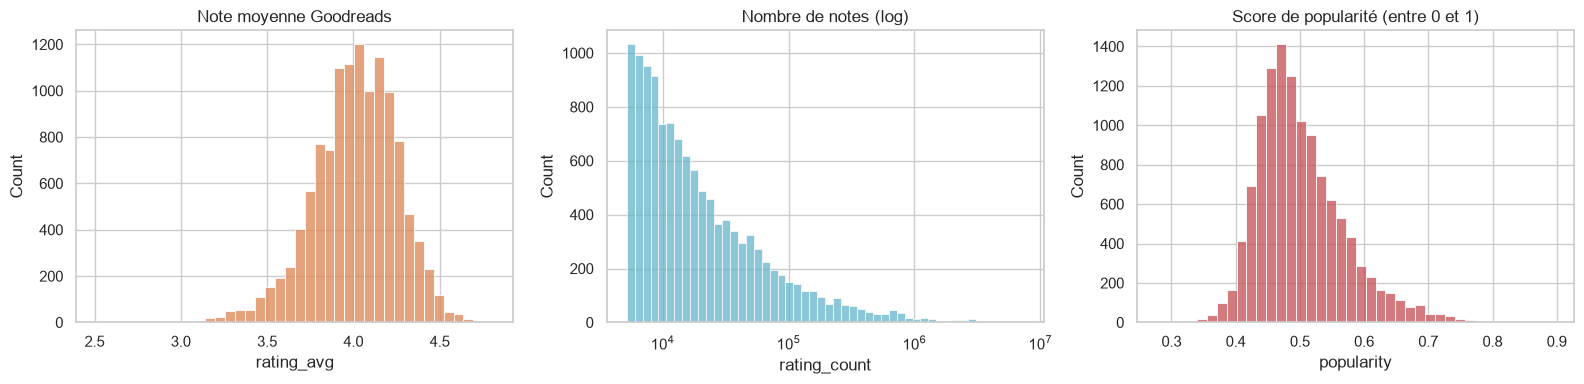

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(catalogue["rating_avg"], bins=40, ax=axes[0], color="#DD8452")
axes[0].set_title("Note moyenne Goodreads")
sns.histplot(catalogue["rating_count"], bins=50, log_scale=True, ax=axes[1], color="#64B5CD")
axes[1].set_title("Nombre de notes (log)")
sns.histplot(catalogue["popularity"], bins=40, ax=axes[2], color="#C44E52")
axes[2].set_title("Score de popularité (entre 0 et 1)")
plt.tight_layout(); save_fig(fig, "catalogue_ratings_popularity"); plt.show()

**Popularity score** (used in P4's final formula):

$$\text{Pop}(j) = \frac{\text{rating\_avg}_j}{5} \times \frac{\log(1+\text{rating\_count}_j)}{\log(1+\max_k \text{rating\_count}_k)}$$

The **logarithm** prevents *Harry Potter* (7 M ratings) from crushing everything: going from 10,000 to 100,000 ratings counts as much as from 100,000 to 1 M.
The `rating_avg/5` factor favours well-liked books, not just well-known ones.

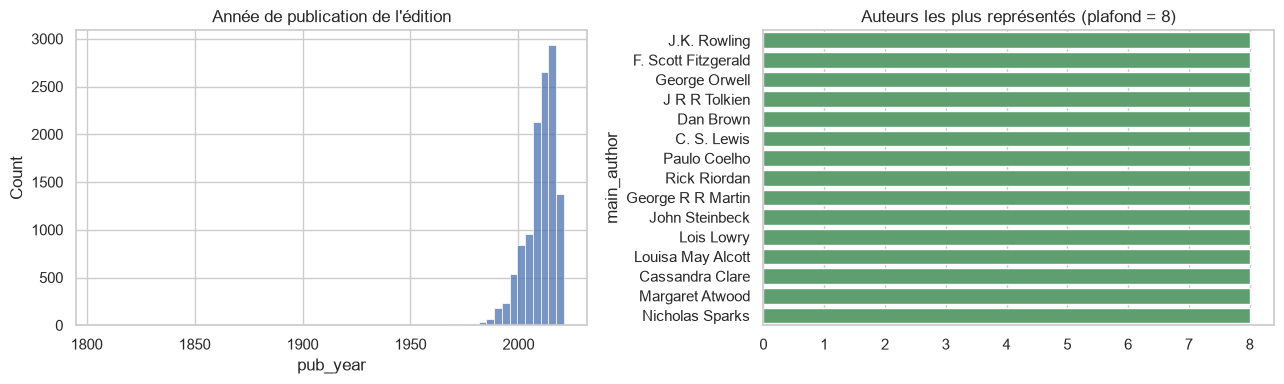

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(catalogue["pub_year"].dropna(), bins=60, ax=axes[0], color="#4C72B0")
axes[0].set_title("Année de publication de l'édition")
top_auth = catalogue["main_author"].value_counts().head(15)
sns.barplot(x=top_auth.values, y=top_auth.index, ax=axes[1], color="#55A868")
axes[1].set_title("Auteurs les plus représentés (plafond = 8)")
plt.tight_layout(); save_fig(fig, "catalogue_years_authors"); plt.show()

⚠️ `pub_year` is the publication year **of the edition** (often a recent reissue) and **not the period of the story**: *Pride and Prejudice* appears there as 2000+.
The period and atmosphere of the story (*Victorian era*, *World War II*…) will therefore be determined **semantically** from the description (*Atmosphere* block, P2).
`pub_year` is only used as an optional filter. Aberrant years (e.g. 2099, a dummy "forthcoming" date) are replaced by missing values.

In [26]:
# Qualitative overview: 5 random books (checking the text quality by eye)
for _, r in catalogue.sample(5, random_state=3).iterrows():
    print(f"■ {r.title} | {r.main_author} | {r.audience} · {r.domain} | {r.categories[:3]}")
    print("  ", r.description[:300], "…\n")

■ I Wish That I Had Duck Feet | Theo LeSieg | Children · Fiction | ['Poetry Books for Kids', 'Animal Stories', 'Funny Books for Kids']
   A young boy weighs the pros and cons of possessing various animal appendages--such as a duck's feet, a deer's antlers, a whale's spout, an elephant's trunk, and a long, long tail--only to decide that he's better off just being himself. A zany, insightful story that beginning readers will wish to hea …

■ Lemon Meringue Pie Murder | Joanne Fluke | Adult · Fiction | ['Crime', 'Crime Fiction']
   The residents of Lake Eden, Minnesota, are planning to paint the town red, white, and blue to celebrate the Fourth of July--but the fireworks are already going off at Hannah Swensen's bake shop, The Cookie Jar... Lemon Meringue Pie Murder Hannah Swensen thought she'd finally discovered the recipe fo …

■ All-of-a-kind Family | Sydney Taylor | Children · Fiction | ["Children's Fiction", "Children's General Story Books", 'Family']
   Meet the All-of-a-Kind Family

## 10. Export and schema

- `books_clean.parquet`: full catalogue.
- `books_sample.parquet`: **500 stratified books** (domain × audience), with P2's enrichment columns (`genres`, `themes`, `styles`, `atmospheres`, `keywords`, `label_scores`) **already present but empty**. The whole team can code against the final schema without waiting.
- Parquet rather than CSV: types preserved (lists, nullable integers), 10× faster reading, file ≈ 5× smaller.

In [27]:
catalogue = catalogue.drop(columns=["n_tokens"])
sample = dl.make_sample(catalogue)
dl.save_parquet(catalogue, config.BOOKS_CLEAN)
dl.save_parquet(sample, config.BOOKS_SAMPLE)
report.to_csv(config.FILTERING_REPORT, index=False)
cat_stats.to_csv(config.CATEGORY_STATS, index=False)
for p in [config.BOOKS_CLEAN, config.BOOKS_SAMPLE, config.FILTERING_REPORT, config.CATEGORY_STATS]:
    print(f"{p.relative_to(ROOT)!s:<45} {p.stat().st_size / 1e6:6.2f} Mo")
print("\nÉchantillon par strate :\n", pd.crosstab(sample["domain"], sample["audience"]))

data/processed/books_clean.parquet             15.52 Mo
data/processed/books_sample.parquet             0.68 Mo
data/reference/filtering_report.csv             0.00 Mo
data/reference/category_stats.csv               0.04 Mo

Échantillon par strate :
 audience     Adult  Children  Young Adult
domain                                   
Fiction        287        55           46
Non-fiction    102         5            5


In [28]:
# Column dictionary (reused in the report)
schema = pd.DataFrame({
    "colonne": catalogue.columns,
    "type": [str(t) for t in catalogue.dtypes],
    "exemple": [str(catalogue.iloc[0][c])[:60] for c in catalogue.columns],
})
schema

,colonne,type,exemple
0,book_id,str,9780590353427
1,title,str,Harry Potter and the Sorcerer's Stone
2,authors,object,['J.K. Rowling']
3,authors_str,str,J.K. Rowling
4,main_author,str,J.K. Rowling
5,categories,object,"[""Children's General Story Books"", 'Sci Fi Books for Kids',"
6,description,str,"Harry Potter has never been the star of a Quidditch team, sc"
7,description_raw,str,"Harry Potter has never been the star of a Quidditch team, sc"
8,pub_year,Int64,1999
9,rating_avg,float64,4.48


## 11. Utilities provided to the rest of the team

Functions of `src/data_loader.py` used by the recommendation engine (P4) and the app (P5):
- `load_books()`: loads the best available catalogue (enriched > clean > sample) and converts the list and JSON columns back;
- `find_author()` / `get_books_by_author()`: **fuzzy** matching (rapidfuzz) of the favourite author typed in the questionnaire, tolerant of typos;
- `apply_constraints()`: boolean mask of the questionnaire's **hard filters** (audience, format, publication period, excluded authors, fiction/non-fiction).

In [29]:
books = dl.load_books(config.BOOKS_CLEAN)
print("'stephen kng'   ->", dl.find_author(books, "stephen kng"))
print("'tolkien'       ->", dl.find_author(books, "tolkien"))
print("'jk rowling'    ->", dl.find_author(books, "jk rowling"))
print("Livres de J.K. Rowling :", dl.get_books_by_author(books, "jk rowling")["title"].tolist())
m = dl.apply_constraints(books, excluded_authors=["J. K. Rowling"])
print("Harry Potter restants après exclusion de Rowling :",
      books.loc[m, "title"].str.startswith("Harry Potter and the").sum())
print(dl.get_books_by_author(books, "agatha christie")[["title", "rating_count"]].head(5), "\n")

mask = dl.apply_constraints(books, audience="Young Adult", formats=["Paperback"],
                            excluded_authors=["Suzanne Collins"], fiction_only=True)
print(f"Young Adult + Paperback + fiction, sans Suzanne Collins : {mask.sum():,} livres")

'stephen kng'   -> Stephen King
'tolkien'       ->

 J R R Tolkien
'jk rowling'    -> J.K. Rowling
Livres de J.K. Rowling : ["Harry Potter and the Sorcerer's Stone", 'Harry Potter and the Prisoner of Azkaban', 'Harry Potter and the Deathly Hallows', 'Harry Potter and the Chamber of Secrets', 'Harry Potter and the Goblet of Fire', 'Harry Potter and the Order of the Phoenix', 'Harry Potter and the Half-Blood Prince', "The Cuckoo's Calling"]
Harry Potter restants après exclusion de Rowling : 0
                                                                                         title  \
295                                                           The Murder on the Orient Express   
437   The Mysterious Affair at Styles : Hercule Poirot's First Case (Hercule Poirot Mysteries)   
1348                                                                 The Man in the Brown Suit   
2086                                                                   The Murder on the Links   
2417                                                              

## 12. Summary of the choices and limitations

| Choice | Justification |
|---|---|
| English only | English SBERT model, English interface, 89% of the dataset |
| Paperback / Hardback | removes 105 k audio CDs, calendars, games: no narrative content |
| Description ≥ 300 characters, without generic or marketing text | **content** is needed for a relevant semantic embedding |
| `rating_count ≥ 50` then top 12,000 by popularity | reliable ratings, recognisable books (demo, evaluation), reasonable cost |
| "Leisure reading" categories | the system recommends according to **literary** preferences |
| Merging editions (union-find) | one work = one row: no duplicates in the top 3 |
| Canonical author spelling | reliable favourite author / excluded authors in the questionnaire |
| Generic text removed sentence by sentence | a good description is not lost because of one "public domain" sentence |
| Marketing removed using the dataset's author names + titles | knowing where an attribution ends without cutting content |
| Spin-off products removed (precise list) | a pop-up book or a "making of" is not a reading experience |
| At most 8 books per author | diversity of the catalogue and of the recommendations |
| Inferred audience (for-ages + categories) | for-ages is missing for 93%; needed for the questionnaire filter |
| Minimal preprocessing | SBERT uses the full context (stopwords, negations, punctuation) |

**Limitations:**
- **Popularity and English-language bias**: the catalogue reflects the sales of a British online bookseller.
- The descriptions are still **editorial texts**: a little marketing remains ("#1 bestselling classic") that the regexes do not fully remove.
- Category classification and audience inference are **rule-based**: a few errors at the margin (e.g. an adult novel labelled *Children's Fiction* by the bookseller).
- `pub_year` is not the period of the story.
- Merging editions rarely makes mistakes: 14 "doubtful" groups (titles without a shared word) out of ≈ 70,000, and they are mostly real variants (*Blindside* / *Blind Side*, translations, poetry collections).
- ≈ 20 descriptions keep a few attribution words ("*via Twitter*"): a deliberately cautious error.

➡️ **Next:** P2 enriches this catalogue (genres, themes, style, atmosphere, keywords → `books_enriched.parquet`), then P3 computes the embeddings.